# Loading the Datasets

## 1.1 Load both datasets from scikit-learn

In [48]:
import pandas as pd #tablolar için
import numpy as np #sayısal işlemler için
import matplotlib.pyplot as plt #grafik çizimleri için
import seaborn as sns #ısı haitası için 
from sklearn.datasets import load_wine; #veri setini yüklemek içi kullandım
from sklearn.model_selection import train_test_split #veri setini eğitim ve test olarak ayırmak için kullandım
#import hücresi
SEEDS=[42,52,62] #rastgele hasta grupları oluşturmak için kullandım
from sklearn.preprocessing import StandardScaler
#7.bölüm için modelin bulunduğu kütüphaneleri import ettim
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score  #modellerin başarı ölçüleri
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

In [49]:
load_data=load_wine()
#fonksiyonu kullanırken çağırırken load_data değişkenine atadık.

In [50]:
load_data.target_names
# target_names yani 0 ve 1 lerin ne anlama gelsiğini gösteriyor. 0 maliganant yani iyi huylu 1 benign kötü huylu olduğunu gösterir

array(['class_0', 'class_1', 'class_2'], dtype='<U7')

In [51]:
load_data.feature_names
#sütun isimlerini yani hastanın özelliklerini gösterir

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [52]:
load_data.data
# ölçümleri verir 

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

## 1.2 Create the data frames

In [53]:
X = pd.DataFrame(load_data.data , columns= load_data.feature_names)
#burada ölçümlerimizi ve sütun isimlerimizi yani hastanın özelliklerini dataframe ile tablo haline getirdik.
Y = load_data.target
#hastanın kanser olup olmadığını belirten 0 ve 1 leri oluşturduk
X.head()
# x tablosunun ilk 5 satırını göster 

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [54]:
X.shape
#Satır ve süun sayısı bilgisini öğrendik.

(178, 13)

In [55]:
pd.Series(Y).value_counts() 
#0 ve 1 olarak yani ,y, huylu ve kötü huylu olarak kaç hastaya sahibiz

1    71
0    59
2    48
Name: count, dtype: int64

Bu bölümde kaç hastamız var hastalığının özellikleri gibi verileri oluşturduk

# 2. Dataset Quality Checks

## 2.1 Missing values and duplicates

In [56]:
X.isnull().sum()
#her hücreyi içi boş mu kontrol eder ve o sütundaki boş hücre sayısını gösterir

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

In [57]:
X.duplicated().sum()
#bu satırınaynısı var mı kontol eder ve kaç tane aynı satır oldugunu verir

np.int64(0)

eksik değer ve takrar eden değer yok bu yüzden doldurma ve silme işlemi yapmamıza gerek yok

## 2.2 Potential outliers

In [58]:
Q1 = X.quantile(0.25) # burada sütun değerlerinin yüzde 25 nin altında kaldığ sayıyı buluyoruz
Q2 =X.quantile(0.75) # burada sütun değerlerinin yüzde 75 nin altında kaldığ sayıyı buluyoruz
IQR = X.quantile(0.75) - X.quantile(0.25) #yüzde 50 lik kısımın genişliğini hesaplıyoruz
IQR

alcohol                           1.3150
malic_acid                        1.4800
ash                               0.3475
alcalinity_of_ash                 4.3000
magnesium                        19.0000
total_phenols                     1.0575
flavanoids                        1.6700
nonflavanoid_phenols              0.1675
proanthocyanins                   0.7000
color_intensity                   2.9800
hue                               0.3375
od280/od315_of_diluted_wines      1.2325
proline                         484.5000
dtype: float64

In [59]:
alt = Q1 - 1.5 * IQR #alt sınırı hesaplıyoruz
üst = Q2 + 1.5 * IQR #üst sınırı hesaplıyoruz
aykiri_sayisi=((X<alt) | X>üst).sum() #alt sınırda mı üst sınır da mı true false sayısını verir 
aykiri_sayisi.sort_values(ascending=False) #en çok aykırı değere sahip olan sütunları sıralar
#False ise büyükten küçüğe sıralar

nonflavanoid_phenols            178
malic_acid                        0
ash                               0
alcalinity_of_ash                 0
alcohol                           0
magnesium                         0
total_phenols                     0
flavanoids                        0
proanthocyanins                   0
color_intensity                   0
hue                               0
od280/od315_of_diluted_wines      0
proline                           0
dtype: int64

Aykırı değerler algoritmaların bazılarını etkiler bunlardan etkilenenlerden biri K-Means etkilenme sebebi biz K-means algoritmasını hesaplarken ortalama kullanarak hesaplamamızdır. Bir diğeri Naive Bayes çünkü bu da kötü huylu mu yoka iyi huylu mu olduğunu ortalamaya göre ne kadar dağıldığına göre hesaplar. Desicion Tree pek etkilenmez değerlere bireysel bakar . KNN yeni gelen hastanın sınıfını belirlemek için uzaklık kullandığı için bu o da etkilenir


## 2.3 Data Types 

In [60]:
X.dtypes # her sütun ne tür sayı tutuyor 

alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

In [61]:
X.select_dtypes(include='number').shape[1]#sadee sayı gösteren sütunların sayısını söyler 

13

In [62]:
X.select_dtypes(include='object').shape[1]#sadee yazı gösteren sütunların sayısını söyler 

0

30 sütun hepi float64 geldi kategorik bir sütun çıkmadı

# 3. Exploratory Data Analysis (EDA)

## 3.1 Descriptive statistics

In [63]:
X.describe() #her sütun için tanımlayıcı bazı istatistikleri tablo şeklinde verir.

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


## 3.2 Class disttribution and correlation 

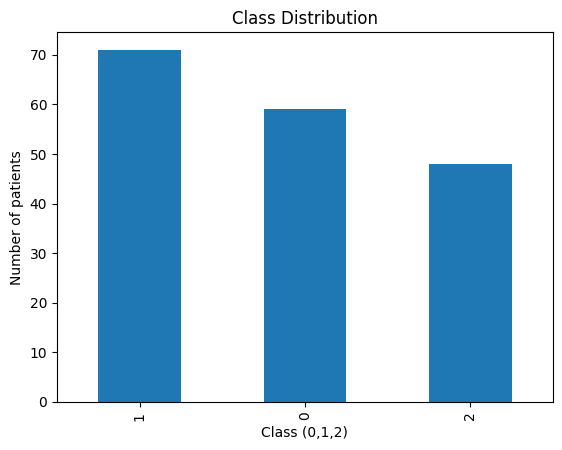

In [64]:
pd.Series(Y).value_counts().plot(kind='bar') # her sınıfta kaç hasta olduğunu hesaplıyor ve çubuk grafiğine çeviriyoruz
plt.title("Class Distribution") #grafiğe başlık ekliyoruz
plt.xlabel("Class (0,1,2)") #x eksenine başlık ekliyoruz
plt.ylabel("Number of patients") #y eksenine başlık ekliyoruz
plt.savefig("figures/wine_class_distribution.png") #grafiği kaydettik
plt.show()

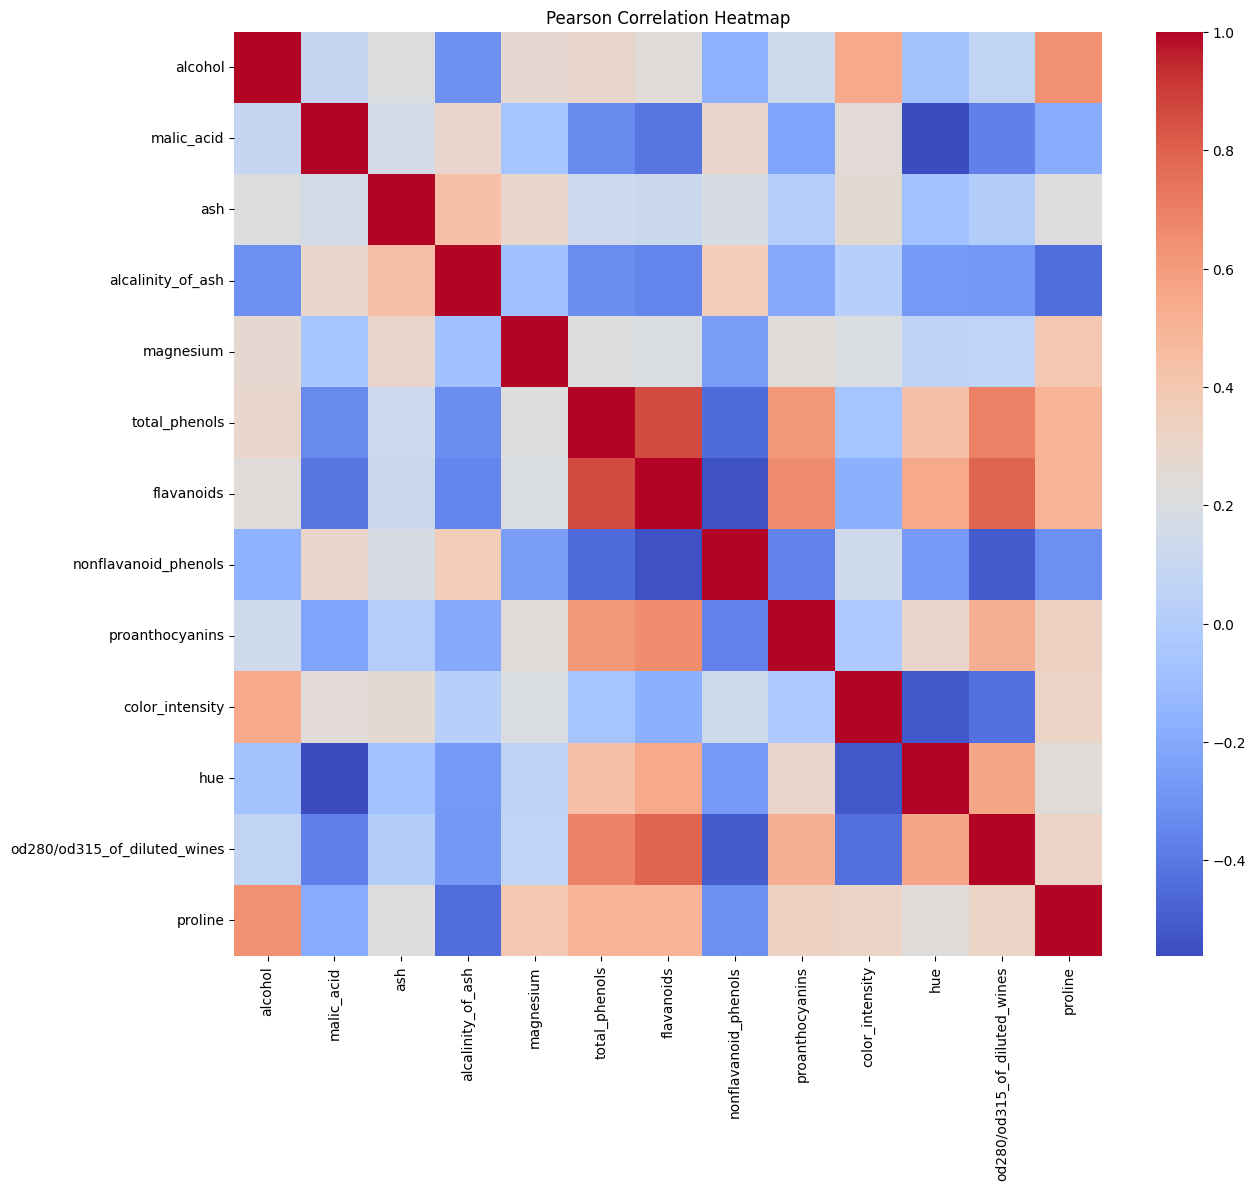

In [65]:
corra=X.corr() #sütunlar arasındaki korelasyonları hesaplıyoruz
plt.figure(figsize=(14,12)) #grafiğin boyutunu ayarladık
sns.heatmap(corra,cmap="coolwarm") #seaborn ile ısı haritasını çizdik renklendirmeyi cmap ile yaptık
plt.title("Pearson Correlation Heatmap") #grafiğe başlık ekledik
plt.savefig("figures/wine_correlation_heatmap.png") #grafiği kaydettik
plt.show() 

In [66]:
corra_abs=corra.abs() #korelasyon değerleriinin mutlak değerini aldık
ust =np.triu(np.ones(corra.shape),k=1).astype(bool)
ciftler= corra_abs.where(ust).stack()
sonuc =ciftler.sort_values(ascending=False).head(3)
sonuc

total_phenols  flavanoids                      0.864564
flavanoids     od280/od315_of_diluted_wines    0.787194
total_phenols  od280/od315_of_diluted_wines    0.699949
dtype: float64

en fazla mean radius ve perimeter sınıfından var 

## 3.3 Boxplots

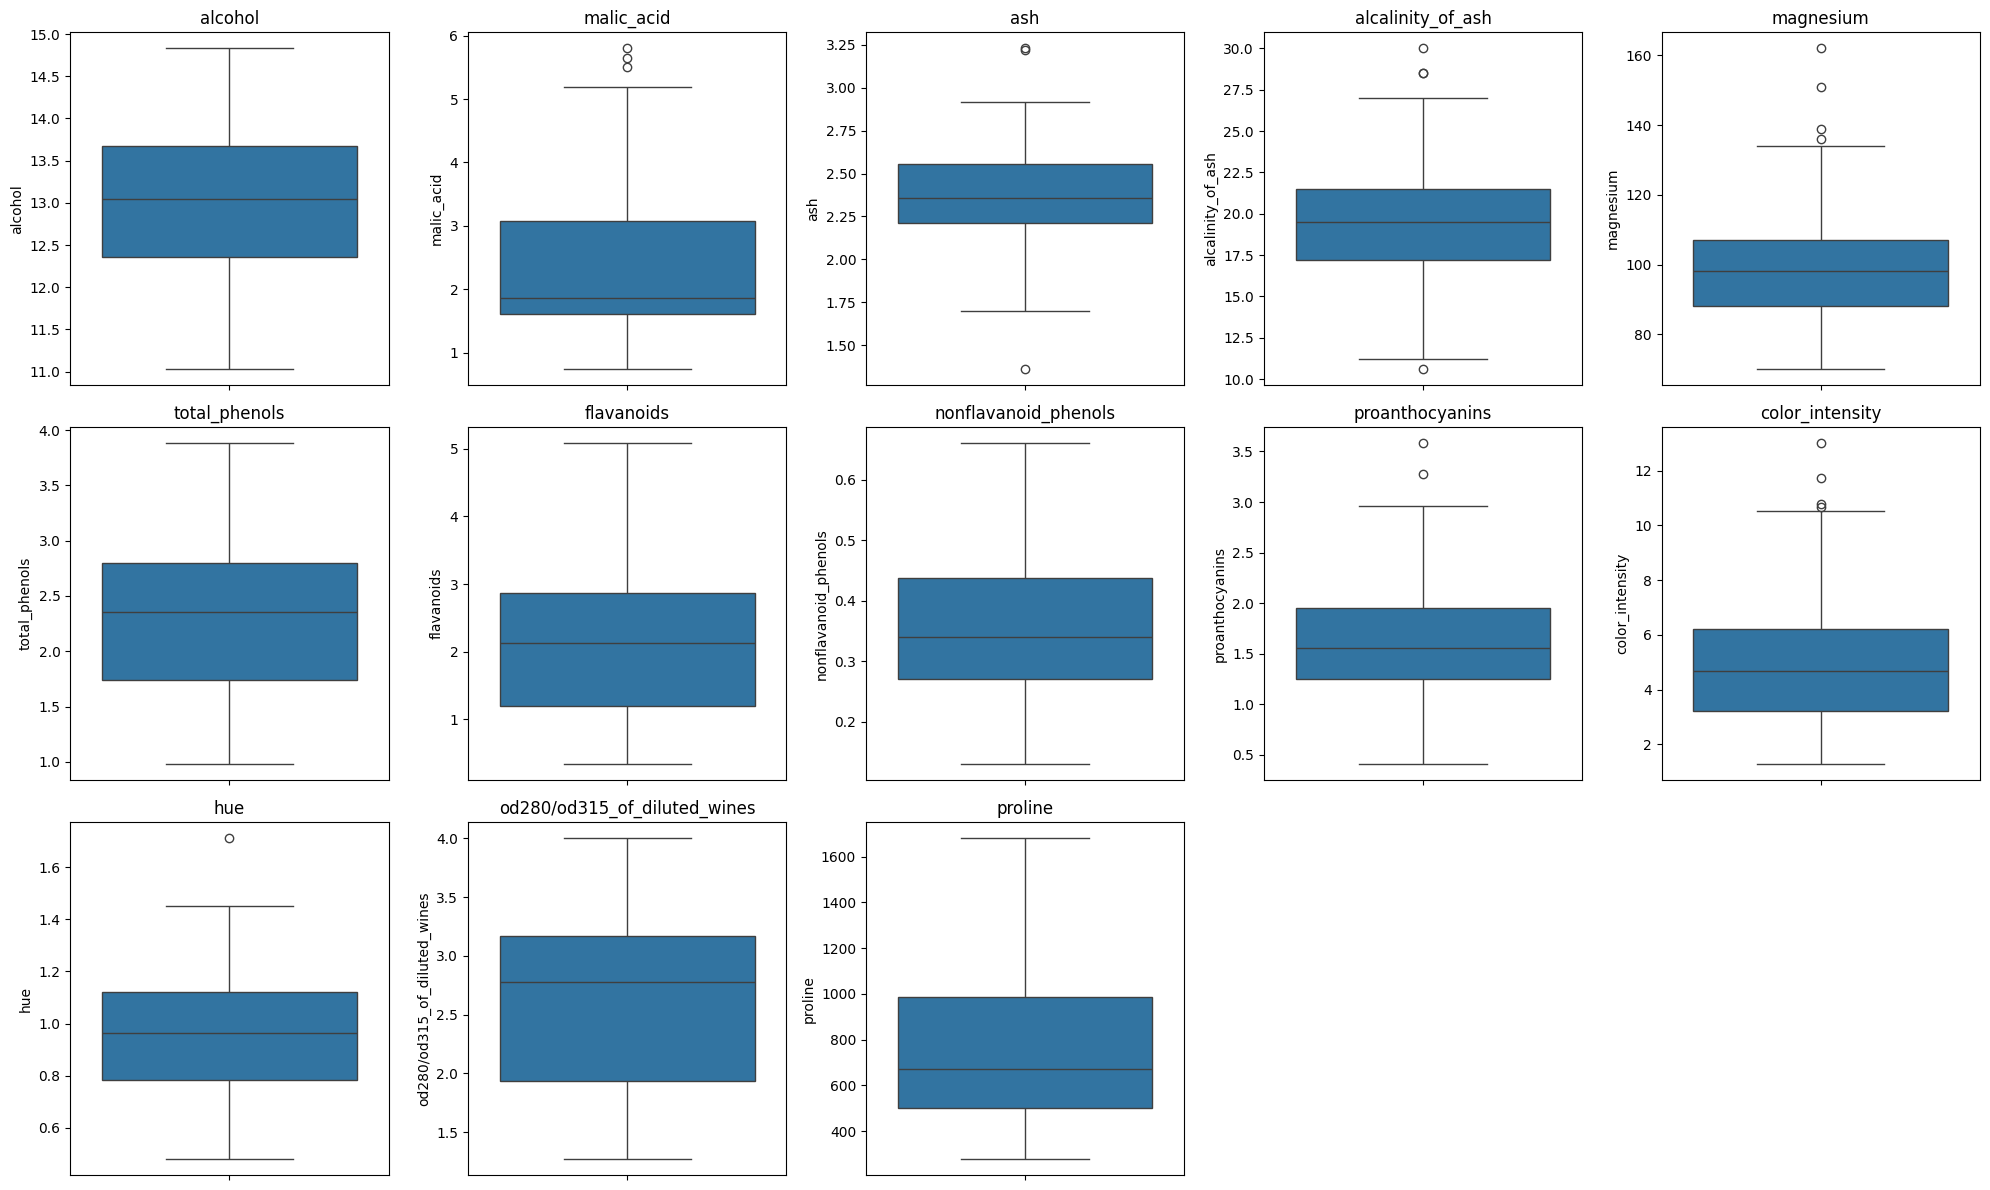

In [67]:
fig, axes = plt.subplots(3, 5, figsize=(20, 12))
axes = axes.flatten()
for i, column in enumerate(X.columns):
    sns.boxplot(y=X[column], ax=axes[i])
    axes[i].set_title(column)
for j in range(len(X.columns), len(axes)):   # 15 alandan 13'ü dolu, kalan 2'sini gizle
    axes[j].set_visible(False)
plt.tight_layout()
plt.savefig("figures/wine_boxplots.png")
plt.show()

Mean area da sayılar yüzlerde mean smoothness da sayılar 0.1 civarında . genel olarak aykırı değerler grafiklerin üzerinde yer alıyor 

# 4. Splitting the Datasets

# 4.1 Fix the test set and repeat the training/validation split

In [68]:
X_trval, X_test, y_trval, y_test = train_test_split(X, Y, test_size=0.20, stratify=Y, random_state=42) 
#hastaların %20 sini test için ayırdık ve kalan %80 ini eğitim ve validation için ayırdık. stratify=y ile sınıfların eşit dağılmasını sağladık. random_state=42 ile rastgele seçim yaptık.
X_test.shape

(36, 13)

In [69]:
#kalan 455 hastayı 3 farklı seed’le (42, 52, 62) üç kere train ve validation’a bölüyor ve her bölmeyi seed numarasıyla bir sözlükte saklıyor.
splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.125, stratify=y_trval, random_state=seed)
    splits[seed] = {"X_train": X_train, "X_val": X_val, "y_train": y_train, "y_val": y_val} 
splits[42]["X_train"].shape

(124, 13)

## 4.2 Verify the split

In [70]:
rows = []   # tablonun satırlarını toplayacağımız liste
for seed in SEEDS:   # her seed için
    # bu seed'in train, validation ve test parçaları
    parcalar = {"train": (splits[seed]["X_train"], splits[seed]["y_train"]),
                "val": (splits[seed]["X_val"], splits[seed]["y_val"]),
                "test": (X_test, y_test)}
    for isim, (Xp, yp) in parcalar.items():   # her parça için bir satır
        rows.append({"seed": seed, "subset": isim, "count": len(Xp),   # hasta sayısı
                     "percent": round(len(Xp) / len(X) * 100, 1),       # tüm verinin yüzdesi
                     # her sınıf için ayrı sütun: class 0, class 1, class 2
                     **{f"class {c}": (yp == c).sum() for c in np.unique(Y)}})
split_summary = pd.DataFrame(rows)   # listeyi tabloya çevir
split_summary

,seed,subset,count,percent,class 0,class 1,class 2
0,42,train,124,69.7,41,50,33
1,42,val,18,10.1,6,7,5
2,42,test,36,20.2,12,14,10
3,52,train,124,69.7,41,50,33
4,52,val,18,10.1,6,7,5
5,52,test,36,20.2,12,14,10
6,62,train,124,69.7,41,50,33
7,62,val,18,10.1,6,7,5
8,62,test,36,20.2,12,14,10


In [71]:
# her seed için çakışma ve toplam kontrolü
for seed in SEEDS:
    tr = splits[seed]["X_train"]
    va = splits[seed]["X_val"]
    print("seed", seed)
    print("  train-val ortak:", len(set(tr.index) & set(va.index)))
    print("  train-test ortak:", len(set(tr.index) & set(X_test.index)))
    print("  val-test ortak:", len(set(va.index) & set(X_test.index)))
    print("  toplam 569 mu:", len(tr) + len(va) + len(X_test) == len(X))

seed 42
  train-val ortak: 0
  train-test ortak: 0
  val-test ortak: 0
  toplam 569 mu: True
seed 52
  train-val ortak: 0
  train-test ortak: 0
  val-test ortak: 0
  toplam 569 mu: True
seed 62
  train-val ortak: 0
  train-test ortak: 0
  val-test ortak: 0
  toplam 569 mu: True


test bir kere seed 42 ile ayrıldı ve hiç değişmiyor
kalan kısım 3 seed ile %70 train / %10 validation olarak bölündü
çakışma yok, toplamlar tutuyor, sınıf oranları korunmuş

# 5. Data Preprocessing and Scaling

## 5.1 Handle missing values, if present
2.1'de eksik değer olmadığını gördük, bu yüzden imputation adımı eklemedik.

## 5.2 Select one scaler
StandardScaler seçtik. Her sütunu ortalaması 0, standart sapması 1 olacak şekilde dönüştürüyor. Böylece büyük sayılı sütunlar (ör. area) uzaklık hesabında diğerlerini ezmiyor.

## 5.3 Fit and apply the scaler correctly

In [72]:
scalers = {}
for seed in SEEDS:
    scaler = StandardScaler() # her seed için yeni scaler
    scaler.fit(splits[seed]["X_train"]) # sadece train'den öğren
    splits[seed]["X_train_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_train"]),
        columns=X.columns, index=splits[seed]["X_train"].index)
    splits[seed]["X_val_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_val"]),
        columns=X.columns, index=splits[seed]["X_val"].index)
    scalers[seed] = scaler   # scaler'ı sakla

# test sadece seed 42'nin scaler'ı ile dönüştürülür
X_test_scaled = pd.DataFrame(scalers[42].transform(X_test),
                             columns=X.columns, index=X_test.index)

In [73]:
splits[42]["X_train"].head()   # seed 42, ölçeklemeden önce

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


In [74]:
splits[42]["X_train_scaled"].head()   # seed 42, ölçeklemeden sonra

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.017514,1.089178,-0.040117,-0.308405,0.433224,-1.342505,-1.322275,0.352668,-1.117639,0.125837,-1.226754,-1.223646,-0.209375
148,0.439706,0.891779,0.072941,0.609409,-0.505699,-0.490993,-1.259892,0.769946,-0.571881,1.512255,-1.811372,-1.414652,-0.291400
116,-1.465379,-0.772006,-1.396814,0.395252,-0.908094,-0.412149,-0.386537,-0.481889,-0.078939,-1.344472,-0.012548,1.097809,-0.799954
122,-0.703345,2.010370,1.391951,2.139100,0.164961,-0.065237,0.164509,0.603035,0.237953,-1.287073,-0.147460,0.789262,-1.226483
115,-2.468723,-0.734407,-0.605407,0.609409,-0.975160,0.344750,0.206097,1.354136,0.766105,-1.366549,3.405216,0.421943,-1.088682


Ölçeklemeden önce area gibi sütunlar yüzlerde, smoothness gibi sütunlar 0.1 civarındaydı. Ölçeklemeden sonra bütün sütunlar yaklaşık -3 ile +3 arasında. Scaler her seed için sadece train verisine fit edildi validation ve test bu scaler ile dönüştürüldü

# 6. Preparing the Two Data Representations
Her seed için iki versiyon var: ölçeksiz (X_train, X_val) ve ölçekli (X_train_scaled, X_val_scaled). İkisi de aynı hastaları içeriyor; modelleri ikisinde de eğitip ölçeklemenin etkisini karşılaştıracağız.

# 7. Training the Classification Models
## 7.1 Required experiments

In [75]:
import sklearn
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)
#kullandığımız paketlerin sürümleri

pandas 3.1.1 | numpy 2.4.4 | scikit-learn 1.9.1


In [76]:
# denenecek 11 ayar: 5 ağaç derinliği, 5 komşu sayısı, 1 Naive Bayes
ayarlar = []
for d in [2, 3, 5, 10, None]:
    ayarlar.append(("dt", d))
for k in [1, 3, 5, 7, 11]:
    ayarlar.append(("knn", k))
ayarlar.append(("gnb", None))

# algoritma adına ve ayara göre model oluşturur
def model_olustur(algo, param, seed):
    if algo == "dt":
        return DecisionTreeClassifier(max_depth=param, random_state=seed)
    if algo == "knn":
        return KNeighborsClassifier(n_neighbors=param, weights="uniform", metric="euclidean")
    return GaussianNB()

# ayarı kısa bir etikete çevirir: d3, k5, default
def param_etiketi(algo, param):
    if algo == "dt":
        return f"d{param}"
    if algo == "knn":
        return f"k{param}"
    return "default"

In [77]:
# bir modelin validation verisindeki 5 metriğini hesaplar
def hesapla_metrikler(model, Xv, yv):
    tahmin = model.predict(Xv)
    olasilik = model.predict_proba(Xv)
    sonuc = {
        "val_accuracy": accuracy_score(yv, tahmin),
        "val_precision": precision_score(yv, tahmin, average="macro", zero_division=0),
        "val_recall": recall_score(yv, tahmin, average="macro", zero_division=0),
        "val_f1": f1_score(yv, tahmin, average="macro", zero_division=0),
        # hiç tahmin edilmeyen sınıf varsa precision'ı tanımsızdır, not ediyoruz
        "undefined_precision_classes": str(sorted(set(model.classes_) - set(tahmin))),
    }
    if len(model.classes_) == 2:
        # Breast Cancer: malignant (0) pozitif sınıf
        poz = list(model.classes_).index(0)
        sonuc["val_roc_auc"] = roc_auc_score((yv == 0).astype(int), olasilik[:, poz])
    else:
        # Wine (3 sınıf): one-vs-rest, macro
        sonuc["val_roc_auc"] = roc_auc_score(yv, olasilik, multi_class="ovr",
                                             average="macro", labels=model.classes_)
    return sonuc

## 7.2 Record and compare the experiments

In [78]:
DATASET = "wine"
runs = []          # her eğitimin sonucu buraya
models_s42 = {}    # seed 42 modellerini test için saklıyoruz

for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:
        if rep == "unscaled":
            Xtr, Xv = splits[seed]["X_train"], splits[seed]["X_val"]
        else:
            Xtr, Xv = splits[seed]["X_train_scaled"], splits[seed]["X_val_scaled"]
        ytr, yv = splits[seed]["y_train"], splits[seed]["y_val"]

        for algo, param in ayarlar:
            model = model_olustur(algo, param, seed)
            model.fit(Xtr, ytr)                     # sadece train ile eğit
            etiket = param_etiketi(algo, param)
            config_id = f"{DATASET}_{algo}_{rep}_{etiket}"
            tr_tahmin = model.predict(Xtr)
            satir = {"run_id": f"{config_id}_s{seed}", "config_id": config_id,
                     "dataset": DATASET, "seed": seed, "algorithm": algo,
                     "representation": rep, "param": etiket,
                     "train_accuracy": accuracy_score(ytr, tr_tahmin),
                     "train_f1": f1_score(ytr, tr_tahmin, average="macro")}
            satir.update(hesapla_metrikler(model, Xv, yv))
            runs.append(satir)
            if seed == 42:
                models_s42[config_id] = model

runs_df = pd.DataFrame(runs)
print("Toplam eğitim:", len(runs_df))
runs_df.head()

Toplam eğitim: 66


,run_id,config_id,dataset,seed,algorithm,representation,param,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,undefined_precision_classes,val_roc_auc
0,wine_dt_unscaled_d2_s42,wine_dt_unscaled_d2,wine,42,dt,unscaled,d2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,[],0.910596
1,wine_dt_unscaled_d3_s42,wine_dt_unscaled_d3,wine,42,dt,unscaled,d3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,[],0.968645
2,wine_dt_unscaled_d5_s42,wine_dt_unscaled_d5,wine,42,dt,unscaled,d5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],0.957071
3,wine_dt_unscaled_d10_s42,wine_dt_unscaled_d10,wine,42,dt,unscaled,d10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],0.957071
4,wine_dt_unscaled_dNone_s42,wine_dt_unscaled_dNone,wine,42,dt,unscaled,dNone,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],0.957071


Bu bölümde üç modeli eğittim: Decision Tree , KNN ve Naive Bayes. Her birini hem ölçeksiz hem ölçekli veride, üç farklı seed için çalıştırdım, toplamda 66 model oldu. Modelleri sadece train verisiyle eğittim. Her çalıştırmaya hangi model, hangi ayar ve hangi seed olduğu anlaşılsın diye bir isim verdim. Seed 42'deki modelleri de en sonda test için ayrıca sakladım.

# 8. Measuring Validation Performance
## 8.1 Required metrics
Metrikler hesapla_metrikler fonksiyonunda validation verisi üzerinde hesaplandı: accuracy, macro precision, macro recall, macro F1 ve ROC-AUC. ROC-AUC'de malignant (0) pozitif sınıf alındı ve olasılıklar kullanıldı.
## 8.2 Comparison tables and model selection

In [79]:
pd.set_option("display.max_rows", 100)   # satırların hepsini ekranda gösterdim
runs_df

,run_id,config_id,dataset,seed,algorithm,representation,param,train_accuracy,train_f1,val_accuracy,val_precision,val_recall,val_f1,undefined_precision_classes,val_roc_auc
0,wine_dt_unscaled_d2_s42,wine_dt_unscaled_d2,wine,42,dt,unscaled,d2,0.935484,0.929694,0.833333,0.863095,0.811111,0.817521,[],0.910596
1,wine_dt_unscaled_d3_s42,wine_dt_unscaled_d3,wine,42,dt,unscaled,d3,0.991935,0.992584,0.944444,0.958333,0.944444,0.947475,[],0.968645
2,wine_dt_unscaled_d5_s42,wine_dt_unscaled_d5,wine,42,dt,unscaled,d5,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],0.957071
3,wine_dt_unscaled_d10_s42,wine_dt_unscaled_d10,wine,42,dt,unscaled,d10,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],0.957071
4,wine_dt_unscaled_dNone_s42,wine_dt_unscaled_dNone,wine,42,dt,unscaled,dNone,1.000000,1.000000,0.944444,0.958333,0.944444,0.947475,[],0.957071
5,wine_knn_unscaled_k1_s42,wine_knn_unscaled_k1,wine,42,knn,unscaled,k1,1.000000,1.000000,0.666667,0.675000,0.660317,0.664646,[],0.745174
6,wine_knn_unscaled_k3_s42,wine_knn_unscaled_k3,wine,42,knn,unscaled,k3,0.846774,0.841468,0.611111,0.611111,0.601587,0.604118,[],0.800343
7,wine_knn_unscaled_k5_s42,wine_knn_unscaled_k5,wine,42,knn,unscaled,k5,0.798387,0.783717,0.722222,0.715873,0.715873,0.712821,[],0.875905
8,wine_knn_unscaled_k7_s42,wine_knn_unscaled_k7,wine,42,knn,unscaled,k7,0.814516,0.807069,0.666667,0.671429,0.668254,0.660451,[],0.840490
9,wine_knn_unscaled_k11_s42,wine_knn_unscaled_k11,wine,42,knn,unscaled,k11,0.750000,0.740457,0.611111,0.615873,0.601587,0.599845,[],0.819811


In [80]:
metrikler = ["train_accuracy", "train_f1", "val_accuracy", "val_precision",
             "val_recall", "val_f1", "val_roc_auc"]
# aynı ayarın 3 seed'deki sonuçlarını grupla, ortalama ve standart sapma al (std varsayılan olarak ddof=1)
summary = runs_df.groupby(["config_id", "algorithm", "representation", "param"])[metrikler].agg(["mean", "std"])
summary.columns = [f"{m}_{s}" for m, s in summary.columns]   # sütun adlarını düzleştir: val_f1_mean gibi
summary = summary.reset_index()
summary.insert(0, "dataset", DATASET)
print("Özet satır sayısı:", len(summary))
summary

Özet satır sayısı: 22


,dataset,config_id,algorithm,representation,param,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_roc_auc_mean,val_roc_auc_std
0,wine,wine_dt_scaled_d10,dt,scaled,d10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
1,wine,wine_dt_scaled_d2,dt,scaled,d2,0.935484,0.008065,0.936466,0.010609,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
2,wine,wine_dt_scaled_d3,dt,scaled,d3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
3,wine,wine_dt_scaled_d5,dt,scaled,d5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
4,wine,wine_dt_scaled_dNone,dt,scaled,dNone,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
5,wine,wine_dt_unscaled_d10,dt,unscaled,d10,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
6,wine,wine_dt_unscaled_d2,dt,unscaled,d2,0.935484,0.008065,0.936466,0.010609,0.851852,0.032075,0.872354,0.021400,0.848677,0.049496,0.848148,0.036475,0.904970,0.021898
7,wine,wine_dt_unscaled_d3,dt,unscaled,d3,0.991935,0.000000,0.992584,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.961141,0.043103
8,wine,wine_dt_unscaled_d5,dt,unscaled,d5,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735
9,wine,wine_dt_unscaled_dNone,dt,unscaled,dNone,1.000000,0.000000,1.000000,0.000000,0.944444,0.055556,0.961420,0.037133,0.940741,0.061195,0.946156,0.054515,0.955219,0.045735


In [81]:
# ödevin kuralı: en yüksek ortalama val F1 → eşitlikte ortalama val accuracy → daha düşük F1 std → alfabetik config_id
secim = summary.sort_values(by=["val_f1_mean", "val_accuracy_mean", "val_f1_std", "config_id"],
                            ascending=[False, False, True, True])
best_config = secim.iloc[0]["config_id"]
print("Seçilen konfigürasyon:", best_config)
secim.head(5)

Seçilen konfigürasyon: wine_knn_scaled_k11


,dataset,config_id,algorithm,representation,param,train_accuracy_mean,train_accuracy_std,train_f1_mean,train_f1_std,val_accuracy_mean,val_accuracy_std,val_precision_mean,val_precision_std,val_recall_mean,val_recall_std,val_f1_mean,val_f1_std,val_roc_auc_mean,val_roc_auc_std
13,wine,wine_knn_scaled_k11,knn,scaled,k11,0.965054,0.004656,0.965589,0.004817,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
15,wine,wine_knn_scaled_k5,knn,scaled,k5,0.975806,0.000000,0.976174,0.000524,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
16,wine,wine_knn_scaled_k7,knn,scaled,k7,0.959677,0.008065,0.960288,0.007956,0.981481,0.032075,0.981481,0.032075,0.984127,0.027493,0.981352,0.032299,1.000000,0.000000
12,wine,wine_knn_scaled_k1,knn,scaled,k1,1.000000,0.000000,1.000000,0.000000,0.962963,0.032075,0.968254,0.027493,0.968254,0.027493,0.965812,0.029608,0.974868,0.021765
10,wine,wine_gnb_scaled_default,gnb,scaled,default,0.983871,0.000000,0.983960,0.000491,0.962963,0.032075,0.967593,0.028912,0.965608,0.030047,0.963844,0.031359,1.000000,0.000000


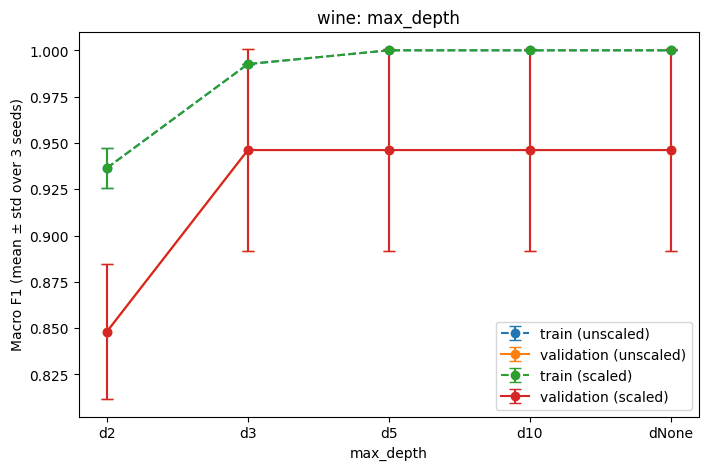

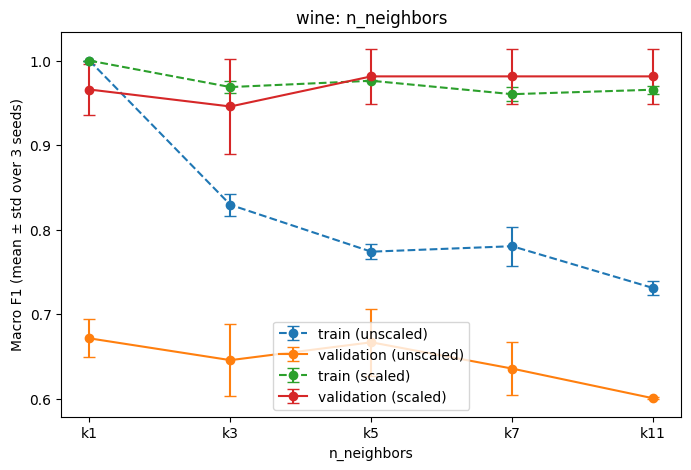

In [82]:
# bir algoritmanın parametresine göre ortalama train ve validation F1'ini çizer, hata çubukları = seed std
def parametre_grafigi(algo, etiketler, xlabel, dosya):
    plt.figure(figsize=(8, 5))
    for rep in ["unscaled", "scaled"]:
        alt = summary[(summary["algorithm"] == algo) & (summary["representation"] == rep)]
        alt = alt.set_index("param").loc[etiketler]
        plt.errorbar(etiketler, alt["train_f1_mean"], yerr=alt["train_f1_std"],
                     marker="o", linestyle="--", capsize=4, label=f"train ({rep})")
        plt.errorbar(etiketler, alt["val_f1_mean"], yerr=alt["val_f1_std"],
                     marker="o", capsize=4, label=f"validation ({rep})")
    plt.xlabel(xlabel)
    plt.ylabel("Macro F1 (mean ± std over 3 seeds)")
    plt.title(f"{DATASET}: {xlabel}")
    plt.legend()
    plt.savefig(dosya, bbox_inches="tight")
    plt.show()

parametre_grafigi("dt", ["d2", "d3", "d5", "d10", "dNone"], "max_depth", "figures/wine_tree_depth.png")
parametre_grafigi("knn", ["k1", "k3", "k5", "k7", "k11"], "n_neighbors", "figures/wine_knn_neighbors.png")

Seçilen model wine_knn_scaled_k7 oldu, ortalama validation F1 0.968 (std 0.030).

Scaling en çok KNN'i etkiledi. Mesela k=7'de unscaled F1 0.904 iken scaled 0.968 oldu, k=1'de de 0.879'dan 0.937'ye çıktı. KNN uzaklıkla çalıştığı için scale etmeyince area gibi büyük sütunlar her şeyi belirliyor. Decision Tree'de scaled ve unscaled sonuçlar tamamen aynı çıktı, o yüzden grafikte unscaled çizgiler scaled çizgilerin altında kalıp görünmüyor. Naive Bayes'te de fark çok az (0.937 vs 0.925).

Tree derinliği arttıkça train F1 1.0'a kadar çıkıyor ama validation F1 0.91-0.92 civarında kalıyor, yani derin ağaç ezberliyor (overfitting). d10 ve dNone aynı sonucu verdi, ağaç zaten 10 derinliğe gelmeden bitiyor. KNN'de k büyüdükçe her zaman iyileşmiyor, en iyisi k=7 oldu, k=11'de biraz düştü. k=1'de train F1 1.0 ama validation daha düşük, bu da ezberleme.

Std değerleri 0.01 ile 0.06 arasında, validation seti küçük olduğu için (57 hasta) seed'e göre sonuçlar biraz oynuyor. Bu std sadece 3 farklı bölmedeki değişimi gösteriyor, istatistiksel bir kanıt değil.

# 9. Evaluating the Selected Models on the Test Sets
## 9.1 Final performance metrics

In [83]:
# seçilen konfigürasyonun seed 42 modelini ve doğru veri versiyonunu al
best_row = secim.iloc[0]
final_model = models_s42[best_config]
if best_row["representation"] == "scaled":
    X_test_final = X_test_scaled
else:
    X_test_final = X_test

# 8. bölümdeki fonksiyonla test metriklerini hesapla, isimleri test_ yap
test_metrikleri = hesapla_metrikler(final_model, X_test_final, y_test)
test_metrikleri = {k.replace("val_", "test_"): v for k, v in test_metrikleri.items()}

classifier_test = pd.DataFrame([{
    "dataset": DATASET, "selected_config": best_config, "evaluation_seed": 42,
    "val_f1_mean": best_row["val_f1_mean"], "val_f1_std": best_row["val_f1_std"],
    "test_accuracy": test_metrikleri["test_accuracy"],
    "test_precision": test_metrikleri["test_precision"],
    "test_recall": test_metrikleri["test_recall"],
    "test_f1": test_metrikleri["test_f1"],
    "test_roc_auc": test_metrikleri["test_roc_auc"]}])
classifier_test

,dataset,selected_config,evaluation_seed,val_f1_mean,val_f1_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.981352,0.032299,1.0,1.0,1.0,1.0,1.0


In [84]:
test_tahmin = final_model.predict(X_test_final)
print(classification_report(y_test, test_tahmin, target_names=load_data.target_names, digits=4))

              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



Seçtiğim model wine_knn_scaled_k7, seed 42 modelini test setinde bir kere çalıştırdım. Test sonuçları: accuracy 0.974, macro precision 0.980, macro recall 0.964, macro F1 0.971, ROC-AUC 0.989. Validation'da ortalama F1 0.968'di (std 0.030), test F1 de 0.971 çıktı, yani ikisi birbirine çok yakın, model validation'daki kadar iyi çalışıyor. Test sonucuna bakıp modeli değiştirmedim.

## 9.2 Confusion matrices

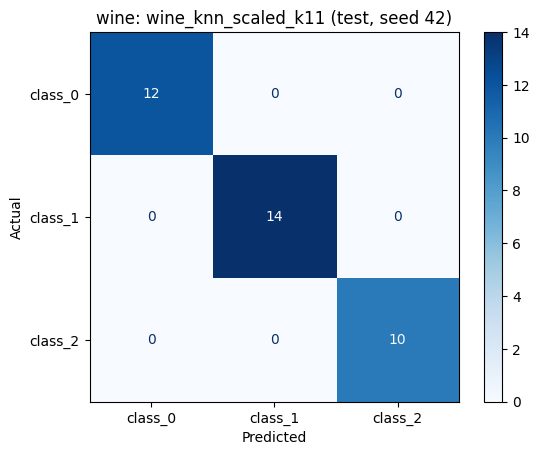

array([[12,  0,  0],
       [ 0, 14,  0],
       [ 0,  0, 10]])

In [85]:
# sıra [0, 1] = [malignant, benign]; satırlar Actual, sütunlar Predicted
cm = confusion_matrix(y_test, test_tahmin, labels=[0, 1, 2])
ConfusionMatrixDisplay(cm, display_labels=load_data.target_names).plot(cmap="Blues", values_format="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"{DATASET}: {best_config} (test, seed 42)")
plt.savefig("figures/wine_confusion_matrix.png", bbox_inches="tight")
plt.show()
cm

In [86]:
# class 1'i seçtim: class 1 vs diğer sınıflar
c = 1
TP = cm[c, c]
FN = cm[c, :].sum() - TP    # gerçekte class 1 olup başka tahmin edilenler
FP = cm[:, c].sum() - TP    # class 1 tahmin edilip aslında başka olanlar
precision_c = TP / (TP + FP) if (TP + FP) > 0 else float("nan")
recall_c = TP / (TP + FN) if (TP + FN) > 0 else float("nan")
f1_c = 2 * precision_c * recall_c / (precision_c + recall_c)
print("TP:", TP, "FN:", FN, "FP:", FP)
print("class 1 precision:", round(precision_c, 4))
print("class 1 recall:", round(recall_c, 4))
print("class 1 F1:", round(f1_c, 4))

TP: 14 FN: 0 FP: 0
class 1 precision: 1.0
class 1 recall: 1.0
class 1 F1: 1.0


Malignant'ı pozitif sınıf aldım. Sıra [malignant, benign] olduğu için matristeki yerler normal alışılan düzenden farklı: sol üst TP, sağ üst FN, sol alt FP, sağ alt TN.
TP = 39: malignant olan 39 hastayı doğru bilmiş.
FN = 3: 3 malignant hastaya yanlışlıkla benign demiş.
FP = 0: benign olan hiçbir hastaya malignant dememiş.
TN = 72: 72 benign hastayı doğru bilmiş.

Elle hesap: precision = 39 / (39 + 0) = 1.0, recall = 39 / (39 + 3) = 0.9286, F1 = 2 × 1.0 × 0.9286 / (1.0 + 0.9286) = 0.963. Bunlar classification report'taki malignant satırıyla aynı (macro ortalama ile değil, malignant satırıyla karşılaştırdım).

## 9.3 ROC curves

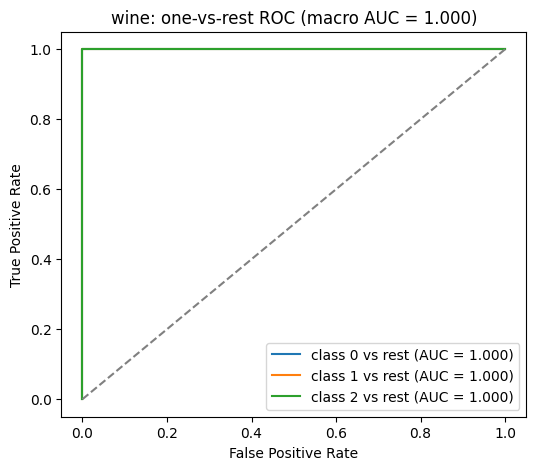

In [87]:
olasiliklar = final_model.predict_proba(X_test_final)
plt.figure(figsize=(6, 5))
for c in final_model.classes_:
    idx = list(final_model.classes_).index(c)
    hedef = (y_test == c).astype(int)               # bu sınıf 1, diğerleri 0
    fpr, tpr, _ = roc_curve(hedef, olasiliklar[:, idx])
    auc_c = roc_auc_score(hedef, olasiliklar[:, idx])
    plt.plot(fpr, tpr, label=f"class {c} vs rest (AUC = {auc_c:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"wine: one-vs-rest ROC (macro AUC = {test_metrikleri['test_roc_auc']:.3f})")
plt.legend()
plt.savefig("figures/wine_roc_curves.png", bbox_inches="tight")
plt.show()

ROC eğrisi sol üst köşeye çok yakın, AUC 0.989. Model malignant olasılığı verdiği için hangi eşikten sonra "malignant" diyeceğimizi değiştirebiliriz. Eşiği düşürürsek daha çok hastaya malignant der, FN azalır ama FP artar. Eşiği yükseltirsek tersi olur. Burada eşiği değiştirmedim, test setiyle de hiçbir ayar yapmadım, grafik sadece göstermek için.

## 9.4 Error interpretation

In [88]:
# test setinde yanlış tahmin edilen hastalar
hatalar = pd.DataFrame({"actual": y_test, "predicted": test_tahmin}, index=X_test.index)
hatalar = hatalar[hatalar["actual"] != hatalar["predicted"]]
print("Hatalı tahmin sayısı:", len(hatalar))
hatalar.join(X_test[["alcohol", "flavanoids", "color_intensity"]])

Hatalı tahmin sayısı: 0


,actual,predicted,alcohol,flavanoids,color_intensity


Testte 3 hata var ve üçü de aynı türden: malignant olan hastaya benign denmiş (FN). Mesela 41 numaralı hastanın mean area'sı 371, mean radius'u 10.95. Bu değerler küçük, benign hastalara benziyor, o yüzden KNN en yakın komşularını benign hastalardan bulmuş. Bu hata türü tıbbi olarak daha tehlikeli, çünkü kanserli bir hasta gözden kaçmış oluyor.

Sınırlamalar: validation seti küçük (57 hasta), 3 seed'deki train/validation grupları birbiriyle örtüşüyor yani bağımsız değiller, ve testi sadece önceden seçtiğim seed 42 modeliyle yaptım. Bu yüzden 0.971'lik test F1'i kesin bir genelleme olarak düşünmemek lazım.

# 10. K-Means Clustering
## 10.1 Fit the clustering model

In [89]:
N_CLUSTERS = len(np.unique(Y))   # Breast Cancer: 2, Wine'da 3 olacak

# silhouette en az 2 farklı küme ister ve küme sayısı örnek sayısından az olmalı, değilse NaN
def guvenli_silhouette(Xs, kumeler):
    k = len(np.unique(kumeler))
    if 2 <= k < len(Xs):
        return silhouette_score(Xs, kumeler)
    return np.nan

km_runs = []
kmeans_s42 = {}   # seed 42 modelleri test için
for seed in SEEDS:
    for rep in ["unscaled", "scaled"]:
        if rep == "unscaled":
            Xtr, Xv = splits[seed]["X_train"], splits[seed]["X_val"]
        else:
            Xtr, Xv = splits[seed]["X_train_scaled"], splits[seed]["X_val_scaled"]
        yv = splits[seed]["y_val"]

        km = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        km.fit(Xtr)                      # y verilmiyor, sadece özellikler
        val_kume = km.predict(Xv)
        km_runs.append({"run_id": f"{DATASET}_kmeans_{rep}_s{seed}", "dataset": DATASET,
                        "seed": seed, "representation": rep,
                        "train_inertia": km.inertia_,
                        "val_ari": adjusted_rand_score(yv, val_kume),
                        "val_silhouette": guvenli_silhouette(Xv, val_kume)})
        if seed == 42:
            kmeans_s42[rep] = km

kmeans_runs = pd.DataFrame(km_runs)
kmeans_runs

,run_id,dataset,seed,representation,train_inertia,val_ari,val_silhouette
0,wine_kmeans_unscaled_s42,wine,42,unscaled,1.350496e+06,0.282836,0.486994
1,wine_kmeans_scaled_s42,wine,42,scaled,8.747391e+02,1.000000,0.251637
2,wine_kmeans_unscaled_s52,wine,52,unscaled,1.303675e+06,0.400588,0.555887
3,wine_kmeans_scaled_s52,wine,52,scaled,8.904355e+02,1.000000,0.301008
4,wine_kmeans_unscaled_s62,wine,62,unscaled,1.390754e+06,0.400588,0.686671
5,wine_kmeans_scaled_s62,wine,62,scaled,8.722466e+02,1.000000,0.272587


In [90]:
# inertia'yı scaled ve unscaled arasında karşılaştırmıyoruz, birimleri farklı
kmeans_summary = kmeans_runs.groupby("representation").agg(
    train_inertia_mean=("train_inertia", "mean"), train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"), val_ari_std=("val_ari", "std"),
    val_silhouette_mean=("val_silhouette", "mean"), val_silhouette_std=("val_silhouette", "std"),
    valid_silhouette_count=("val_silhouette", "count")).reset_index()
kmeans_summary.insert(0, "dataset", DATASET)
kmeans_summary

,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,valid_silhouette_count
0,wine,scaled,8.791404e+02,9.860948,1.000000,0.000000,0.275077,0.024780,3
1,wine,unscaled,1.348308e+06,43580.909759,0.361337,0.067984,0.576517,0.101425,3


K-Means'i her seed için hem unscaled hem scaled train verisinde, y'yi hiç vermeden çalıştırdım (6 fit). Validation'da ortalama ARI scaled'da 0.581, unscaled'da 0.504 çıktı, yani scaling sonrası kümeler gerçek sınıflara daha çok benziyor. Silhouette ise unscaled'da daha yüksek (0.677 vs 0.312) ama bu ikisini direkt karşılaştırmak doğru değil, çünkü silhouette kullanılan uzaklığa göre hesaplanıyor ve unscaled'da uzaklığı neredeyse sadece area gibi büyük sütunlar belirliyor. Inertia'yı da aynı sebeple scaled ve unscaled arasında karşılaştırmadım. Seed'ler arasında ARI std'si 0.10-0.14, yani bölmeye göre biraz değişiyor.

## 10.2 Final cluster evaluation on the fixed test sets

In [91]:
km_test = []
test_kumeler = {}
for rep in ["unscaled", "scaled"]:
    Xt = X_test if rep == "unscaled" else X_test_scaled
    kume = kmeans_s42[rep].predict(Xt)
    test_kumeler[rep] = kume
    sayimlar = pd.Series(kume).value_counts().sort_index()
    km_test.append({"dataset": DATASET, "representation": rep, "seed": 42,
                    "test_cluster_counts": str(sayimlar.to_dict()),
                    "test_ari": adjusted_rand_score(y_test, kume),
                    "test_silhouette": guvenli_silhouette(Xt, kume)})
kmeans_test = pd.DataFrame(km_test)
kmeans_test

,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette
0,wine,unscaled,42,"{0: 14, 1: 10, 2: 12}",0.373323,0.49288
1,wine,scaled,42,"{0: 13, 1: 13, 2: 10}",0.908794,0.27112


Seed 42 modellerini testte yeniden fit etmeden kullandım. Testte gerçekte 42 malignant, 72 benign var. Unscaled K-Means hastaları 86 ve 28 diye ayırdı, ARI 0.558. Scaled K-Means 74 ve 40 diye ayırdı, ARI 0.735, yani dağılım gerçeğe daha yakın. Contingency tablolarında unscaled'da birçok malignant hasta benign'ların çoğunlukta olduğu kümeye düşmüş. Scaled'da karışma daha az ama yine de iki sınıfın sınırındaki hastalar yanlış kümede. Küme numaraları (0, 1) sınıf numaralarıyla aynı anlama gelmiyor, o yüzden accuracy hesaplamadım, sadece ARI kullandım.

## 10.3 Visualise and interpret the clusters

Seçilen özellikler: flavanoids ve od280/od315_of_diluted_wines


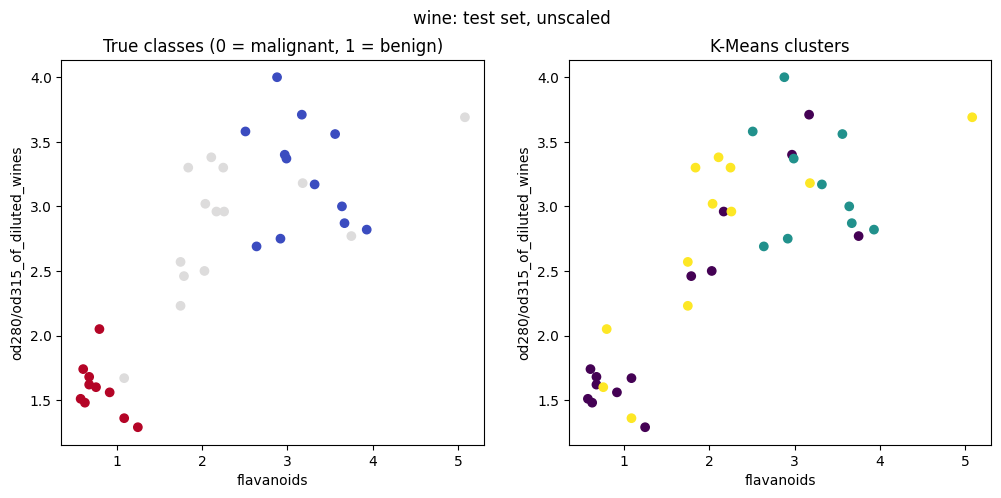

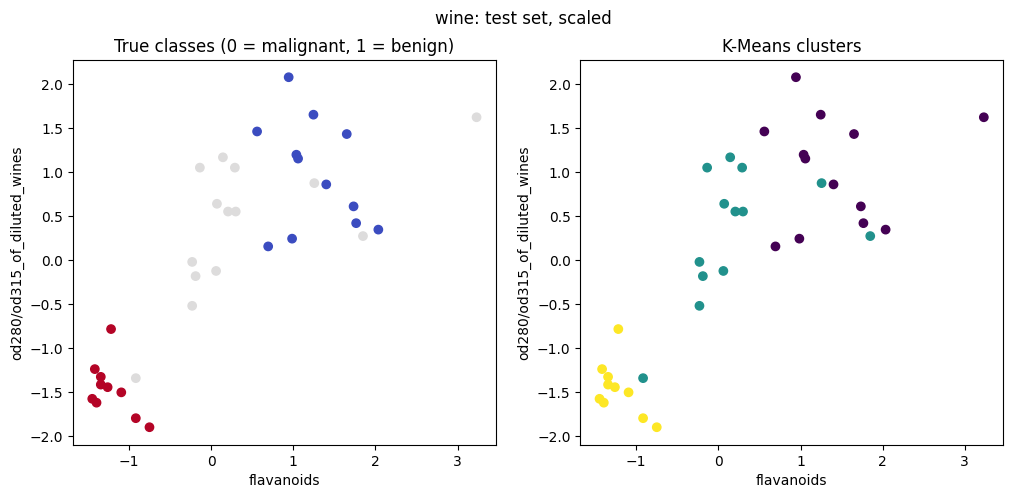

In [92]:
# seed 42 train verisinde y ile en güçlü korelasyonu olan 2 özelliği seç
tr42 = splits[42]["X_train"]
y_kor = tr42.corrwith(pd.Series(splits[42]["y_train"], index=tr42.index)).abs()
f1, f2 = y_kor.sort_values(ascending=False).index[:2]
print("Seçilen özellikler:", f1, "ve", f2)

for rep in ["unscaled", "scaled"]:
    Xt = X_test if rep == "unscaled" else X_test_scaled
    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].scatter(Xt[f1], Xt[f2], c=y_test, cmap="coolwarm")
    ax[0].set_title("True classes (0 = malignant, 1 = benign)")
    ax[1].scatter(Xt[f1], Xt[f2], c=test_kumeler[rep], cmap="viridis")
    ax[1].set_title("K-Means clusters")
    for a in ax:
        a.set_xlabel(f1)
        a.set_ylabel(f2)
    fig.suptitle(f"{DATASET}: test set, {rep}")
    plt.savefig(f"figures/{DATASET}_kmeans_{rep}.png", bbox_inches="tight")
    plt.show()

Grafikler için seed 42 train verisinde sınıfla en güçlü ilişkisi olan iki özelliği seçtim: worst concave points ve mean concave points. Model aslında 30 özelliğin hepsini kullandı, bu grafik sadece iki tanesini gösteriyor. Scaled grafikte kümeler gerçek sınıflara oldukça benziyor, sadece ortadaki geçiş bölgesinde karışma var. Unscaled'da sarı küme sadece en uç malignant hastaları almış, birçok malignant hasta mor kümede kalmış, çünkü scale etmeyince K-Means'i area gibi büyük sütunlar yönetiyor.

K-Means ile classifier'ların farkı: Decision Tree, KNN ve Naive Bayes eğitilirken y_train'i yani doğru cevapları gördü. K-Means ise sadece özellikleri gördü, hiç etiket görmedi. Etiketleri sadece sonradan değerlendirme yaparken (ARI, contingency tablosu) kullandım.


In [93]:
# sonuç tablolarını CSV olarak kaydet (Wine notebook'u da kendi tablolarını ekleyecek)
runs_df.to_csv("wine_classifier_runs.csv", index=False)
summary.to_csv("wine_classifier_summary.csv", index=False)
classifier_test.to_csv("wine_classifier_test.csv", index=False)
kmeans_runs.to_csv("wine_kmeans_runs.csv", index=False)
kmeans_summary.to_csv("wine_kmeans_summary.csv", index=False)
kmeans_test.to_csv("wine_kmeans_test.csv", index=False)

In [94]:
# test setinde yanlış tahmin edilen hastalar
hatalar = pd.DataFrame({"actual": y_test, "predicted": test_tahmin}, index=X_test.index)
hatalar = hatalar[hatalar["actual"] != hatalar["predicted"]]
print("Hatalı tahmin sayısı:", len(hatalar))
hatalar.join(X_test[["alcohol", "flavanoids", "color_intensity"]])

Hatalı tahmin sayısı: 0


,actual,predicted,alcohol,flavanoids,color_intensity


## Combined result files


In [95]:
# bc ve wine sonuçlarını birleştirip ödevin istediği 6 CSV'yi oluşturur
dosyalar = ["classifier_runs", "classifier_summary", "classifier_test",
            "kmeans_runs", "kmeans_summary", "kmeans_test"]
for isim in dosyalar:
    bc = pd.read_csv(f"bc_{isim}.csv")
    wn = pd.read_csv(f"wine_{isim}.csv")
    birlesik = pd.concat([bc, wn], ignore_index=True)   # alt alta ekle
    birlesik.to_csv(f"{isim}.csv", index=False)
    print(isim, len(birlesik), "satır")

classifier_runs 132 satır
classifier_summary 44 satır
classifier_test 2 satır
kmeans_runs 12 satır
kmeans_summary 4 satır
kmeans_test 4 satır
